In [1]:
import pandas as pd
import re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

In [2]:
research_doc_1 = open("C:/Users/jlevi/Desktop/UNI/ITNPA4- 14/Research corpus zip/research_corpus/research_1.txt", encoding = "utf-8").read()
research_doc_2 = open("C:/Users/jlevi/Desktop/UNI/ITNPA4- 14/Research corpus zip/research_corpus/research_2.txt", encoding = "utf-8").read()
research_doc_3 = open("C:/Users/jlevi/Desktop/UNI/ITNPA4- 14/Research corpus zip/research_corpus/research_3.txt", encoding = "utf-8").read()
research_doc_4 = open("C:/Users/jlevi/Desktop/UNI/ITNPA4- 14/Research corpus zip/research_corpus/research_4.txt", encoding = "utf-8").read()
research_doc_5 = open("C:/Users/jlevi/Desktop/UNI/ITNPA4- 14/Research corpus zip/research_corpus/research_5.txt", encoding = "utf-8").read()

df = pd.DataFrame({"Research Documents":[research_doc_1,research_doc_2,research_doc_3,research_doc_4,research_doc_5]})
df.head()

,Research Documents
0,The purposes of this article are to position m...
1,"Now I see it, now I don’t:\nresearcher’s posit..."
2,DEVELOPMENTAL RESEARCH: STUDIES OF\nINSTRUCTIO...
3,Abstract\nCronbach’s alpha is a statistic comm...
4,Denzin’s Paradigm Shift: Revisiting Triangulat...


In [3]:
#denoising
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):

    text = text.lower()

    text = re.sub(r"http\S+|www\S+", "", text)

    words = text.split()

    words = [word for word in words if word not in stop_words]

    words = [lemmatizer.lemmatize(word) for word in words]

    text = " ".join(words)

    return text

df["Clean_Research Documents"] = df["Research Documents"].apply(preprocess_text)

In [4]:
import re
from collections import Counter

article = df["Clean_Research Documents"].iloc[0]

sentences = re.split(r'(?<=[.!?])\s+', article)
words = re.findall(r'\b[a-zA-Z]+\b', article.lower())
word_frequency = Counter(words)

#score each sentence
sentence_scores = {}

for sentence in sentences:
    words_in_sentence = re.findall( r'\b[a-zA-Z]+\b',sentence.lower() )
    score = sum(word_frequency[word]for word in words_in_sentence)
    sentence_scores[sentence] = score
top_sentences = sorted(sentence_scores,key=sentence_scores.get,reverse=True)[:10]

#summary
for sentence in top_sentences:
    print(sentence)
    print()

purpose writing article present mixed method research third research paradigm educational research.5 hope field move beyond quantitative versus qualitative research argument because, recognized mixed method research, quantitative qualitative research important useful.

purpose article position mixed method research (mixed research synonym) natural complement traditional qualitative quantitative research, present pragmatism offering attractive philosophical partner mixed method research, provide framework designing conducting mixed method research.

this, briefly review paradigm “wars” incompatibility thesis, show commonality quantitative qualitative research, explain tenet pragmatism, explain fundamental principle mixed research apply it, provide specific set design two major type mixed method research (mixed-model design mixed-method designs), and, finally, explain mixed method research following (recursively) eight-step process.

basic agreement reached following issues: (a) relativi

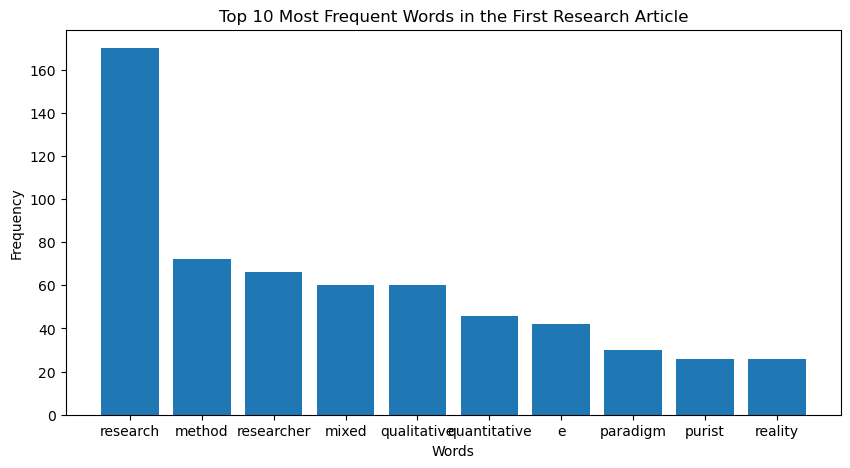

In [5]:
import matplotlib.pyplot as plt

text = df["Clean_Research Documents"].iloc[0]
words = re.findall(r'\b[a-z]+\b', text)
word_frequency = Counter(words)
top_words = word_frequency.most_common(10)
words = [word[0] for word in top_words]
frequencies = [word[1] for word in top_words]

plt.figure(figsize=(10, 5))
plt.bar(words, frequencies)
plt.title("Top 10 Most Frequent Words in the First Research Article")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.show()

In [6]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import TruncatedSVD
import numpy as np
import re
import matplotlib.pyplot as plt

remaining_articles = df["Clean_Research Documents"].iloc[1:]

sentences = []
for article in remaining_articles:
    article_sentences = re.split(r'(?<=[.!?])\s+', article)
    for sentence in article_sentences:
        sentence = sentence.strip()
        if len(sentence.split()) >= 8:
            if not re.fullmatch(r'[\W\d\s]+', sentence):
                sentences.append(sentence)


vectorizer = CountVectorizer(stop_words="english",max_df=0.95)
count_matrix = vectorizer.fit_transform(sentences)

#LSA
n_components = min(5,count_matrix.shape[0] - 1,count_matrix.shape[1] - 1)
lsa = TruncatedSVD(n_components=n_components,random_state=42)
lsa_matrix = lsa.fit_transform(count_matrix)

sentence_scores = np.linalg.norm(lsa_matrix, axis=1)
top_indices = np.argsort(sentence_scores)[-10:]
top_indices = sorted(top_indices)
lsa_summary = [sentences[i] for i in top_indices]

print("LSA Summary:\n")
for sentence in lsa_summary:
    print(sentence)
    print()



LSA Summary:

benefit challenge reflexivity three type researcher’s position discussed illustrated mean case examples: (1) reflexivity researcher share experience study participants, (2) reflexivity researcher move position outsider position insider course study, (3) reflexivity researcher personal familiarity experience studied.

reflexivity increasingly recognized crucial strategy process generating knowledge mean qualitative research (ahmed dunya et al., 2011; blaxter et al., 2006; d’cruz et al., 2007; gerstl-pepin patrizion, 2009; hammersley atkinson, 2002; horsburgh, 2003; koch harrington, 1998).for example, journal forum: qualitative research dedicated full issue (may 2003) subjectivity reflexivity qualitative research, corresponding author: roni berger, school social work, adelphi university, 1 south avenue, garden city, ny 11530, usa.

simplest form, developmental research either  study process impact specific instructional design development efforts;  situation someone perfo

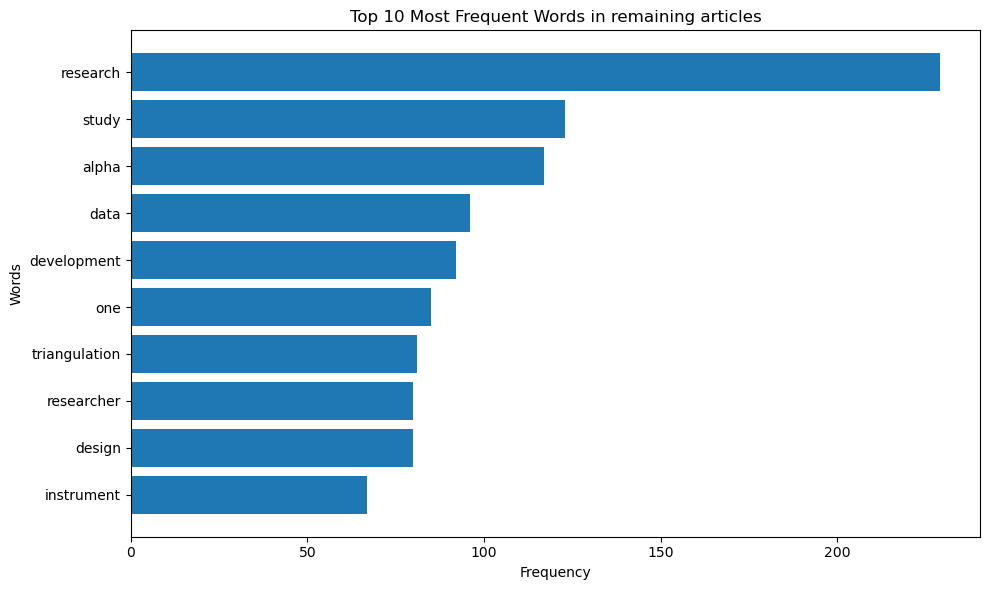

In [7]:
from collections import Counter
import matplotlib.pyplot as plt
import re

text = " ".join(df["Clean_Research Documents"].iloc[1:])

words = re.findall(r'\b[a-z]{3,}\b', text.lower())
word_frequency = Counter(words)
top_words = word_frequency.most_common(10)

terms = [item[0] for item in top_words]
frequencies = [item[1] for item in top_words]

plt.figure(figsize=(10, 6))
plt.barh(terms[::-1], frequencies[::-1])
plt.xlabel("Frequency")
plt.ylabel("Words")
plt.title("Top 10 Most Frequent Words in remaining articles")
plt.tight_layout()
plt.show()


In [8]:

from sklearn.decomposition import LatentDirichletAllocation

documents = df["Clean_Research Documents"]

vectorizer = CountVectorizer()
word_matrix = vectorizer.fit_transform(documents)

lda = LatentDirichletAllocation(n_components=5, random_state=42)
lda.fit(word_matrix)

words = vectorizer.get_feature_names_out()

for i in range(5):
    top_words = lda.components_[i].argsort()[-10:][::-1]
    print("Topic", i+1, ":")
    print(words[top_words])
    print()


Topic 1 :
['research' 'researcher' 'data' 'qualitative' 'method' 'study' 'one'
 'design' 'triangulation' 'development']

Topic 2 :
['interchangeably' 'constantly' 'children' 'consensus' 'attend' 'ways'
 'confidence' '37' 'lost' 'independent']

Topic 3 :
['interchangeably' 'constantly' 'children' 'consensus' 'attend' 'ways'
 'confidence' '37' 'lost' 'independent']

Topic 4 :
['alpha' 'cronbach' 'instrument' 'value' 'reliability' 'science' 'study'
 'item' 'scale' 'education']

Topic 5 :
['interchangeably' 'constantly' 'children' 'consensus' 'attend' 'ways'
 'confidence' '37' 'lost' 'independent']



In [9]:
#distribution
distribution = lda.transform(word_matrix)

topic_df = pd.DataFrame(distribution,columns=[f"Topic {i+1}" for i in range(5)])

print(topic_df.round(3))

   Topic 1  Topic 2  Topic 3  Topic 4  Topic 5
0    1.000      0.0      0.0      0.0      0.0
1    0.999      0.0      0.0      0.0      0.0
2    1.000      0.0      0.0      0.0      0.0
3    0.000      0.0      0.0      1.0      0.0
4    1.000      0.0      0.0      0.0      0.0


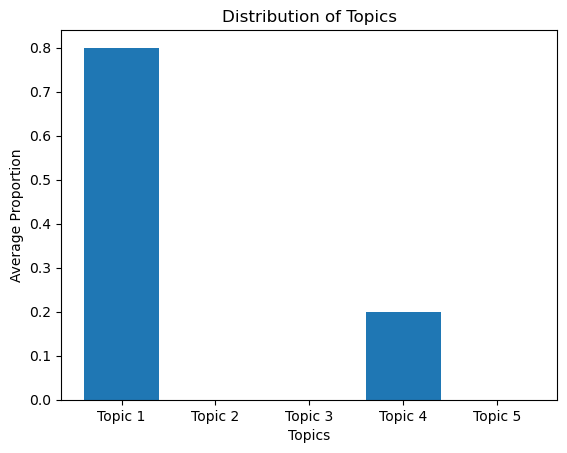

In [10]:
topic_dis_visual = distribution.mean(axis=0)

plt.bar(["Topic 1", "Topic 2", "Topic 3", "Topic 4", "Topic 5"], topic_dis_visual)
plt.title("Distribution of Topics")
plt.xlabel("Topics")
plt.ylabel("Average Proportion")
plt.show()


In [11]:
import pyLDAvis
import pyLDAvis.lda_model

visual = pyLDAvis.lda_model.prepare(lda, word_matrix, vectorizer)

pyLDAvis.display(visual)
